# Cognifyz Data Analysis Internship - Level 1
**Name:** Gaurav Govind Nikam
**Dataset:** Restaurant dataset (Dataset_.csv)

Tasks in this level:
1. Top Cuisines
2. City Analysis
3. Price Range Distribution
4. Online Delivery

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

In [2]:
# loading the data (utf-8-sig because the file has a BOM at the start)
df = pd.read_csv('Dataset_.csv', encoding='utf-8-sig')
print(df.shape)
df.head()

(9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order menu  9551 non-n

In [4]:
# checking missing values
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [5]:
# duplicates check
print('duplicate rows:', df.duplicated().sum())
print('duplicate restaurant ids:', df['Restaurant ID'].duplicated().sum())

duplicate rows: 0
duplicate restaurant ids: 0


Only the `Cuisines` column has missing values (9 rows). There are no duplicates, so the data is mostly clean. I will drop those 9 rows only where I actually need cuisines (Task 1), I don't want to remove them from the other tasks.

## Task 1 - Top Cuisines
- Find top 3 most common cuisines
- Percentage of restaurants serving each of them

One restaurant can have many cuisines written in one cell like `"French, Japanese, Desserts"`, so first I have to split them.

In [6]:
cuisine_df = df.dropna(subset=['Cuisines']).copy()
print('restaurants with cuisine info:', len(cuisine_df))

# split by comma and make one row per cuisine
all_cuisines = cuisine_df['Cuisines'].str.split(',').explode().str.strip()
cuisine_counts = all_cuisines.value_counts()
cuisine_counts.head(10)

restaurants with cuisine info: 9542


Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Name: count, dtype: int64

In [7]:
top3 = cuisine_counts.head(3)
total_restaurants = len(cuisine_df)

top3_pct = (top3 / total_restaurants * 100).round(2)
result = pd.DataFrame({'Restaurants': top3, 'Percentage (%)': top3_pct})
result

,Restaurants,Percentage (%)
Cuisines,,
North Indian,3960,41.50
Chinese,2735,28.66
Fast Food,1986,20.81


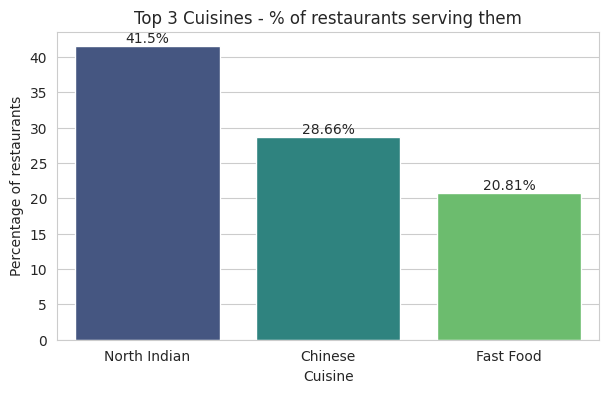

In [8]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=top3.index, y=top3_pct.values, palette='viridis')
for i, v in enumerate(top3_pct.values):
    ax.text(i, v + 0.5, f'{v}%', ha='center')
plt.title('Top 3 Cuisines - % of restaurants serving them')
plt.ylabel('Percentage of restaurants')
plt.xlabel('Cuisine')
plt.show()

**Observation:**
- The top 3 cuisines are **North Indian (3960 restaurants, ~41.5%)**, **Chinese (2735, ~28.7%)** and **Fast Food (1986, ~20.8%)**.
- The percentages add up to more than 100% because one restaurant can serve more than one cuisine.
- North Indian is served by almost 4 out of 10 restaurants. This makes sense as most of the data is from Delhi NCR.

## Task 2 - City Analysis
- City with highest number of restaurants
- Average rating of restaurants in each city
- City with highest average rating

In [9]:
city_counts = df['City'].value_counts()
print('Total cities:', df['City'].nunique())
city_counts.head(10)

Total cities: 141


City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64

In [10]:
print('City with most restaurants:', city_counts.index[0], '-', city_counts.iloc[0])

City with most restaurants: New Delhi - 5473


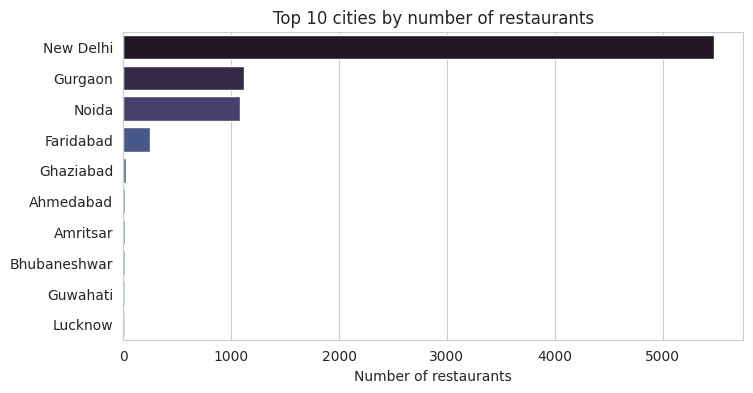

In [11]:
plt.figure(figsize=(8, 4))
sns.barplot(x=city_counts.head(10).values, y=city_counts.head(10).index, palette='mako')
plt.title('Top 10 cities by number of restaurants')
plt.xlabel('Number of restaurants')
plt.ylabel('')
plt.show()

In [12]:
# average rating per city
city_rating = df.groupby('City')['Aggregate rating'].agg(['mean', 'count']).round(2)
city_rating.columns = ['avg_rating', 'num_restaurants']
city_rating = city_rating.sort_values('avg_rating', ascending=False)
city_rating.head(10)

,avg_rating,num_restaurants
City,,
Inner City,4.90,2
Quezon City,4.80,1
Makati City,4.65,2
Pasig City,4.63,3
Mandaluyong City,4.62,4
Beechworth,4.60,1
London,4.54,20
Taguig City,4.53,4
Secunderabad,4.50,2


The top spots here are cities with only 1 or 2 restaurants (like Inner City has 2 and Quezon City has 1). An average of 1-2 restaurants is not really reliable, so I will also check it only for cities having at least 20 restaurants.

In [13]:
big_cities = city_rating[city_rating['num_restaurants'] >= 20].sort_values('avg_rating', ascending=False)
print('Cities with 20+ restaurants:', len(big_cities))
big_cities.head(10)

Cities with 20+ restaurants: 77


,avg_rating,num_restaurants
City,,
London,4.54,20
Orlando,4.47,20
Tampa Bay,4.41,20
Rest of Hawaii,4.41,20
Bangalore,4.38,20
Dubai,4.37,20
Chennai,4.31,20
Ankara,4.30,20
Abu Dhabi,4.30,20


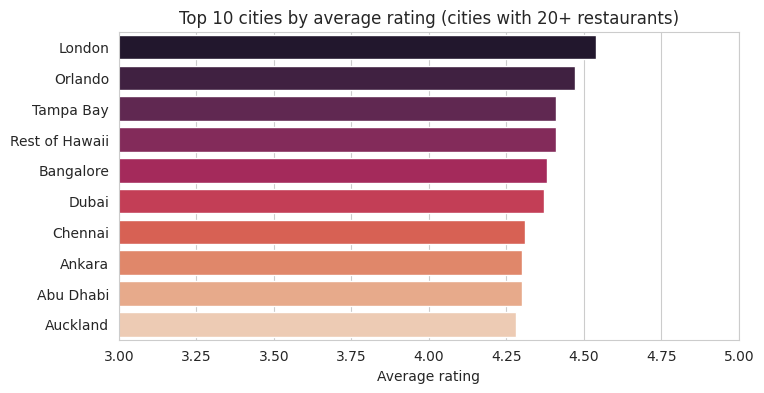

In [14]:
plt.figure(figsize=(8, 4))
top_big = big_cities.head(10)
sns.barplot(x=top_big['avg_rating'], y=top_big.index, palette='rocket')
plt.title('Top 10 cities by average rating (cities with 20+ restaurants)')
plt.xlabel('Average rating')
plt.ylabel('')
plt.xlim(3, 5)
plt.show()

In [15]:
print('Highest avg rating (any city):', city_rating.index[0], city_rating['avg_rating'].iloc[0])
print('Highest avg rating (20+ restaurants):', big_cities.index[0], big_cities['avg_rating'].iloc[0])

Highest avg rating (any city): Inner City 4.9
Highest avg rating (20+ restaurants): London 4.54


**Observation:**
- **New Delhi** has the highest number of restaurants (5473), then Gurgaon (1118) and Noida (1080).
- If I take all cities, **Inner City** is on top with 4.9 but it has just 2 restaurants, so this is not a fair comparison.
- Among cities with 20+ restaurants, **London (4.54)** has the highest average rating, followed by Orlando, Tampa Bay, Rest of Hawaii and Bangalore.
- New Delhi has lots of restaurants but its average rating is only 2.44, because around 26% of its restaurants have 0 rating (not rated yet).

## Task 3 - Price Range Distribution
- Histogram / bar chart of price ranges
- Percentage of restaurants in each price range

In [16]:
price_counts = df['Price range'].value_counts().sort_index()
price_pct = (df['Price range'].value_counts(normalize=True).sort_index() * 100).round(2)

pd.DataFrame({'Restaurants': price_counts, 'Percentage (%)': price_pct})

,Restaurants,Percentage (%)
Price range,,
1,4444,46.53
2,3113,32.59
3,1408,14.74
4,586,6.14


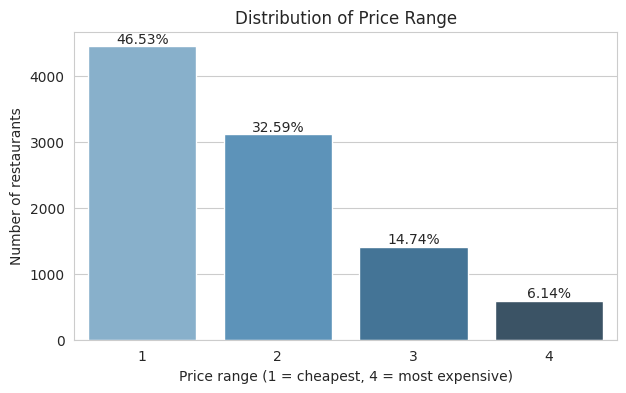

In [17]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(x='Price range', data=df, palette='Blues_d')
for i, v in enumerate(price_pct.values):
    ax.text(i, price_counts.values[i] + 50, f'{v}%', ha='center')
plt.title('Distribution of Price Range')
plt.xlabel('Price range (1 = cheapest, 4 = most expensive)')
plt.ylabel('Number of restaurants')
plt.show()

**Observation:**
- Price range 1 has the most restaurants (**46.53%**), then range 2 (**32.59%**), range 3 (**14.74%**) and range 4 (**6.14%**).
- So nearly 8 out of 10 restaurants (about 79%) are in the cheap or budget categories (1 and 2). The count keeps falling as price goes up.

## Task 4 - Online Delivery
- Percentage of restaurants offering online delivery
- Compare average rating with and without online delivery

In [18]:
delivery_counts = df['Has Online delivery'].value_counts()
delivery_pct = (df['Has Online delivery'].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({'Restaurants': delivery_counts, 'Percentage (%)': delivery_pct})

,Restaurants,Percentage (%)
Has Online delivery,,
No,7100,74.34
Yes,2451,25.66


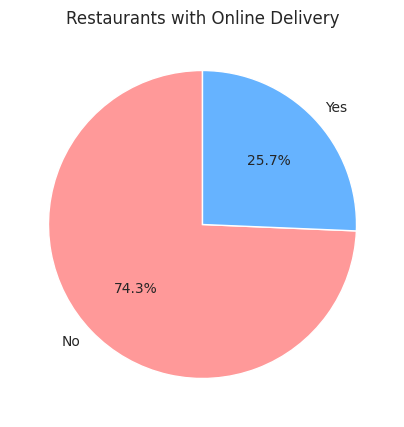

In [19]:
plt.figure(figsize=(5, 5))
plt.pie(delivery_counts, labels=delivery_counts.index, autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=90)
plt.title('Restaurants with Online Delivery')
plt.show()

In [20]:
avg_delivery = df.groupby('Has Online delivery')['Aggregate rating'].mean().round(2)
avg_delivery

Has Online delivery
No     2.47
Yes    3.25
Name: Aggregate rating, dtype: float64

The ratings above also include restaurants with 0 rating (not rated, these are not real ratings). Let me check once more only with rated restaurants so that the comparison is fair.

In [21]:
rated = df[df['Aggregate rating'] > 0]
print('Rated restaurants:', len(rated))
avg_delivery_rated = rated.groupby('Has Online delivery')['Aggregate rating'].mean().round(2)
avg_delivery_rated

Rated restaurants: 7403


Has Online delivery
No     3.47
Yes    3.38
Name: Aggregate rating, dtype: float64

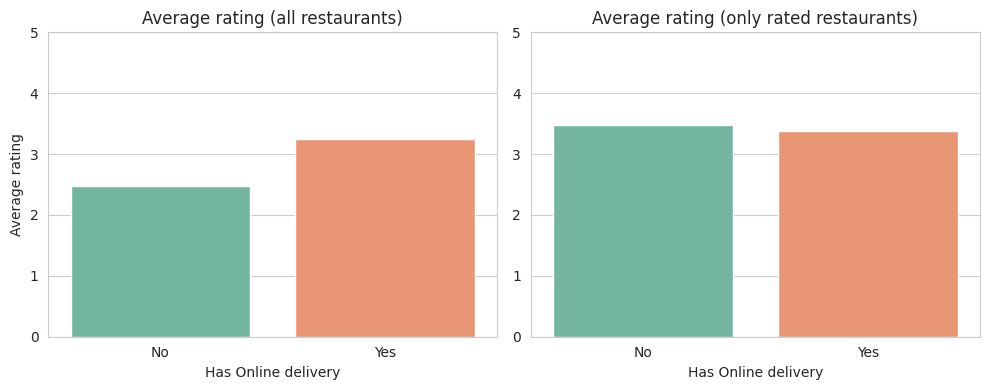

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(x=avg_delivery.index, y=avg_delivery.values, ax=axes[0], palette='Set2')
axes[0].set_title('Average rating (all restaurants)')
axes[0].set_ylabel('Average rating')
sns.barplot(x=avg_delivery_rated.index, y=avg_delivery_rated.values, ax=axes[1], palette='Set2')
axes[1].set_title('Average rating (only rated restaurants)')
axes[1].set_ylabel('')
for ax in axes:
    ax.set_xlabel('Has Online delivery')
    ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()

**Observation:**
- Only **25.66%** of the restaurants offer online delivery, the other **74.34%** do not.
- Average rating with online delivery is **3.25** and without it is **2.47** (all restaurants).
- But this gap is mostly caused by the unrated (0) restaurants, because they are much more common among restaurants without delivery. When I take only rated restaurants (7403), the result flips: **without delivery 3.47** and **with delivery 3.38**, so there is almost no difference (restaurants without delivery are even slightly higher).
- So I can say that online delivery does not really make a restaurant better rated. The first result looked big only because of the 0 ratings.

---
**Level 1 completed.**